In [34]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder, MinMaxScaler, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from lightgbm import LGBMRegressor
from reg_helper import *
from plots import *
from timeit import default_timer as timer
import random
from scipy.stats import randint as sp_randint
from scipy.stats import uniform as sp_uniform
from skopt.space import Integer, Real, Categorical
from skopt import BayesSearchCV


In [35]:
%load_ext autoreload
%autoreload 2
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [36]:
data = pd.read_csv('diamonds.csv')
df_preprocessed = data.copy()
print(df_preprocessed.shape)

df_preprocessed = df_preprocessed.drop(['Unnamed: 0'], axis=1)
df_preprocessed.drop_duplicates(inplace=True) #удалим дубликаты
df_preprocessed = df_preprocessed[(df_preprocessed[['x', 'y', 'z']] != 0).all(axis=1)].copy()


df_preprocessed['depth_counted'] = df_preprocessed['z'] * 2 / (df_preprocessed['x'] + df_preprocessed['y']) * 100
df_preprocessed['depth_diff'] = abs(df_preprocessed['depth'] - df_preprocessed['depth_counted'])
index_to_drop = df_preprocessed[df_preprocessed['depth_diff'] > 1].index
df_preprocessed = df_preprocessed.drop(index=index_to_drop)
df_preprocessed.drop(['depth_counted', 'depth_diff'], axis=1, inplace=True)

df_preprocessed.shape

(53940, 11)


(53695, 10)

In [37]:
ordered_categories = {
    'cut': ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'],
    'color': ['J', 'I', 'H', 'G', 'F', 'E', 'D'],
    'clarity': ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']
}
numeric_features = ['carat', 'depth', 'table', 'x', 'y', 'z']

preprocessor = Pipeline(steps=[
    ('column_transformer', ColumnTransformer(
        transformers=[
            ('ordinal_encoder',
             OrdinalEncoder(categories=[
                 ordered_categories['cut'],
                 ordered_categories['color'],
                 ordered_categories['clarity']
             ]),
             list(ordered_categories.keys())),

            ('num', StandardScaler(), numeric_features)
        ],
        verbose_feature_names_out=False
    ))
])

preprocessor.set_output(transform="pandas")

,steps,"[('column_transformer', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal_encoder', ...), ('num', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_we

In [38]:
X, y = divide_data(df_preprocessed, 'price')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

In [39]:
base_model = ('LGBMClassifier', LGBMRegressor(random_state=SEED))
preprocessor.steps.append(base_model)
pipeline = preprocessor

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001213 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1281
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 9
[LightGBM] [Info] Start training from score 3938.566859


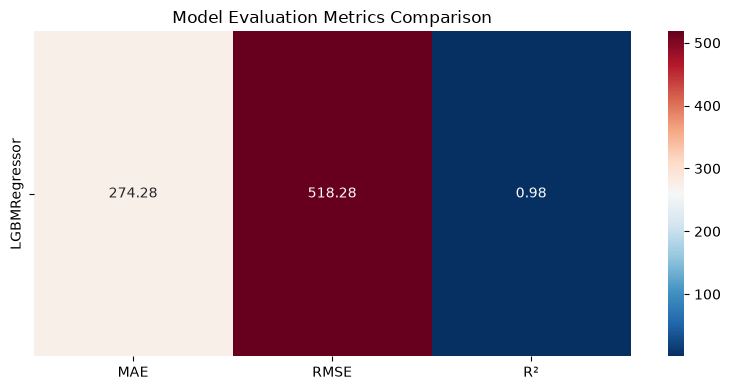

In [40]:
initial_metrics = train_evaluate_models(
    models=[('LGBMRegressor', pipeline)],
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    seed=SEED
)

In [41]:
base_model[1].get_params()

{'boosting_type': 'gbdt',
 'class_weight': None,
 'colsample_bytree': 1.0,
 'importance_type': 'split',
 'learning_rate': 0.1,
 'max_depth': -1,
 'min_child_samples': 20,
 'min_child_weight': 0.001,
 'min_split_gain': 0.0,
 'n_estimators': 100,
 'n_jobs': None,
 'num_leaves': 31,
 'objective': None,
 'random_state': 42,
 'reg_alpha': 0.0,
 'reg_lambda': 0.0,
 'subsample': 1.0,
 'subsample_for_bin': 200000,
 'subsample_freq': 0}

In [42]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

# Random Search

In [50]:
param_distributions = {
    'LGBMClassifier__n_estimators': [200, 300, 500, 700, 1000],
    'LGBMClassifier__learning_rate': [0.01, 0.03, 0.05, 0.07, 0.1],
    'LGBMClassifier__num_leaves': [15, 31, 63, 127],
    'LGBMClassifier__max_depth': [4, 6, 8, 10, 12, -1],
    'LGBMClassifier__min_child_samples': [5, 10, 20, 40, 80],
    'LGBMClassifier__reg_lambda': [0, 0.1, 1, 5, 10]
}

In [51]:
randomized_search = RandomizedSearchCV(
    random_state=SEED,
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=100,
    scoring='neg_mean_squared_error',
    cv=cv,
    n_jobs=1,
    verbose=3
)


In [52]:
randomized_search_start = timer()
randomized_search.fit(X_train, y_train)
randomized_search_end = timer()

Fitting 5 folds for each of 100 candidates, totalling 500 fits
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000888 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1272
[LightGBM] [Info] Number of data points in the train set: 34364, number of used features: 9
[LightGBM] [Info] Start training from score 3937.002881
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain

In [53]:
print(f"Total time: {randomized_search_end - randomized_search_start:.2f} seconds")

Total time: 421.97 seconds


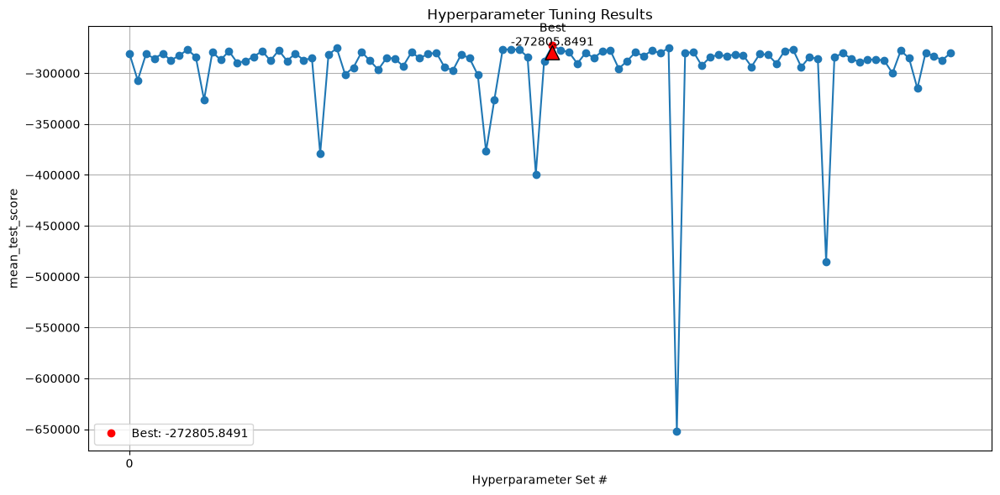

In [54]:
data = plot_hyperparam_search_results(randomized_search.cv_results_, xtick_step=100)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001147 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1281
[LightGBM] [Info] Number of data points in the train set: 42956, number of used features: 9
[LightGBM] [Info] Start training from score 3938.566859
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gai

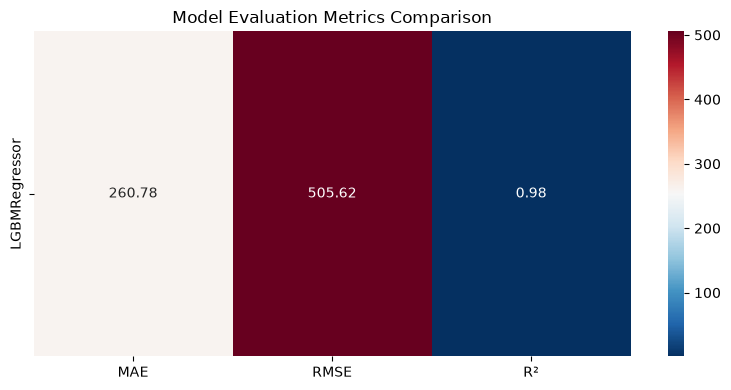

In [55]:
randomized_search_metrics = train_evaluate_models(
    models=[('LGBMRegressor', randomized_search.best_estimator_)],
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    seed=SEED
)


In [58]:
randomized_search.best_params_

{'LGBMClassifier__reg_lambda': 0.1,
 'LGBMClassifier__num_leaves': 127,
 'LGBMClassifier__n_estimators': 500,
 'LGBMClassifier__min_child_samples': 5,
 'LGBMClassifier__max_depth': 6,
 'LGBMClassifier__learning_rate': 0.03}

(<Figure size 800x400 with 2 Axes>,
                      MAE       RMSE        R²
 LGBMRegressor -13.499972 -12.658641  0.000831)

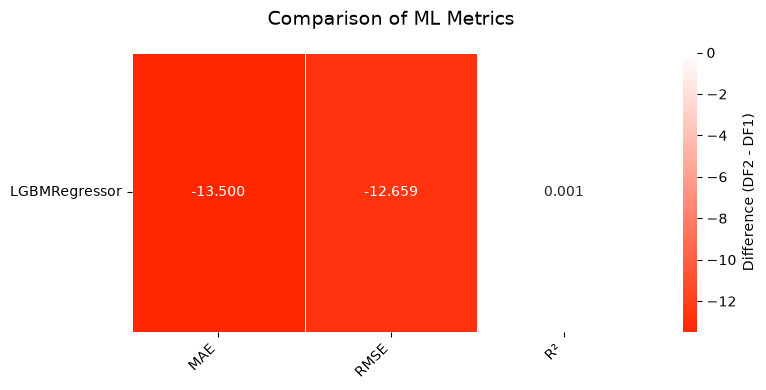

In [56]:
compare_metrics_heatmap(initial_metrics, randomized_search_metrics)